# OCT EDA

run `hash.py`, `dupe.py` and `standardize.py` first

mostly for sanity checking other stuff and ensure consistency across classes/splits/patients etc

In [19]:
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import standardize

DATA_FOLDER = standardize.DATA_FOLDER
CLEAN_FOLDER = standardize.OUTPUT_FOLDER
HASHES_CSV = DATA_FOLDER / "image_hashes.csv"
CLASSES = standardize.CLASSES
SPLITS = standardize.SPLITS
SEED = 7615
THREADS = max(1, (getattr(os, "process_cpu_count", os.cpu_count)() or 1) - 2)  # leave two threads free

for path in [HASHES_CSV, standardize.OMIT_CSV, standardize.LOG_CSV, CLEAN_FOLDER]:
    if not path.exists():
        raise FileNotFoundError(f"{path} not found, run hash.py, dupe.py and standardize.py first")

hashes = pd.read_csv(HASHES_CSV, dtype=str)
omit = pd.read_csv(standardize.OMIT_CSV, dtype=str)
log = pd.read_csv(standardize.LOG_CSV)
log["split"] = log["file"].str.split("/").str[0]
log["class"] = log["file"].str.split("/").str[1]

print(f"hashed: {len(hashes):,}, omitted: {len(omit):,}, cleaned: {len(log):,}")

hashed: 109,309, omitted: 8,135, cleaned: 101,174


In [20]:
plt.rcParams["figure.constrained_layout.use"] = True
CLASS_COLORS = {"CNV": "#2a78d6", "DME": "#eb6834", "DRUSEN": "#1baf7a", "NORMAL": "#eda100"}
COLORS = [CLASS_COLORS[c] for c in CLASSES]


def class_bars(ax, values, title, fmt="{:,.0f}"):
    """bar chart with one labelled bar per class, values is a series indexed by class"""
    heights = [values[c] for c in CLASSES]
    bars = ax.bar(CLASSES, heights, color=COLORS)
    ax.bar_label(bars, labels=[fmt.format(h) for h in heights])
    ax.set_title(title)
    ax.margins(y=0.15)


def class_boxes(ax, df, column, title):
    """box plot with one box per class, whiskers at the 1st and 99th percentiles, no outliers"""
    data = [df.loc[df["class"] == c, column] for c in CLASSES]
    boxes = ax.boxplot(data, tick_labels=CLASSES, whis=(1, 99), showfliers=False,
                       patch_artist=True, medianprops={"color": "black"})
    for box, color in zip(boxes["boxes"], COLORS):
        box.set_facecolor(color)
    ax.set_title(title)


def show_image(ax, path, title):
    """draws a grayscale image file with no axis ticks"""
    with Image.open(path) as image:
        ax.imshow(image.convert("L"), cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8)

## 1. raw data check

In [21]:
LEVELS = np.arange(256) # 0-255 for pixels


def histogram_stats(hist):
    """mean, std and percentiles from a 256 bin histogram to cheat a bit and save resources over reading iamges"""
    hist = np.array(hist, dtype=float)
    n = hist.sum()
    cdf = np.cumsum(hist) / n
    mean = (hist * LEVELS).sum() / n
    std = np.sqrt((hist * (LEVELS - mean) ** 2).sum() / n)
    median = np.searchsorted(cdf, 0.5)
    p99 = np.searchsorted(cdf, 0.99)
    return {"mean": mean, "std": std, "median": median, "p99": p99}


def read_raw(task):
    """opens one raw image and returns its size and some pixel stats"""
    split, class_name, path = task
    row = {"file": standardize.relative_name(path), "split": split, "class": class_name, "error": None}
    try:
        with Image.open(path) as image:
            gray = image.convert("L")
    except Exception as error:
        row["error"] = str(error)
        return row
    width, height = gray.size
    hist = gray.histogram()
    corners = [gray.getpixel((0, 0)), gray.getpixel((width - 1, 0)),
               gray.getpixel((0, height - 1)), gray.getpixel((width - 1, height - 1))]
    row["size"] = f"{width}x{height}"
    row.update(histogram_stats(hist))
    row["near_white"] = sum(hist[240:]) / (width * height)
    row["white_corner"] = int(max(corners) >= 240)  # same rule standardize.py uses to find wedges
    return row


# multithreading because we don't have all day
files = standardize.find_image_files(SPLITS)
with ThreadPoolExecutor(THREADS) as pool:
    raw = pd.DataFrame(pool.map(read_raw, files))

failed = raw[raw["error"].notna()]
raw = raw[raw["error"].isna()]
raw = raw.merge(hashes[["file", "patient"]], on="file")
print(f"{len(raw) + len(failed):,} raw images, {len(failed):,} failed to open")

109,309 raw images, 0 failed to open


### 1.1 train images by class

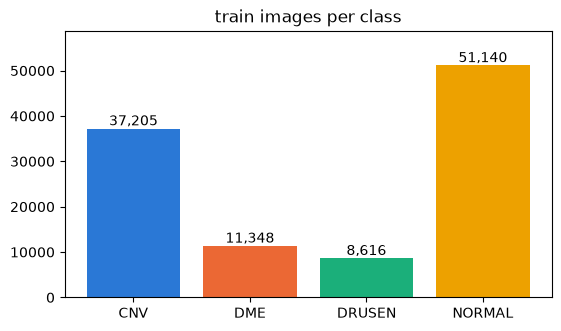

NORMAL has 5.9x as many observations as DRUSEN


In [22]:
train_counts = raw.loc[raw["split"] == "train", "class"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 3.2))
class_bars(ax, train_counts, "train images per class")
plt.show()
print(f"{train_counts.idxmax()} has {train_counts.max() / train_counts.min():.1f}x as many observations as {train_counts.idxmin()}")

### 1.2 patients by class

In [23]:
patients = raw.groupby(["split", "class"])["patient"].nunique().unstack()
patients.loc[SPLITS]

class,CNV,DME,DRUSEN,NORMAL
split,,,,
train,791,709,713,3434
test,178,167,169,171


### 1.3 patients found in more than one class

group images by patient ID to avoid leakage across splits

In [24]:
classes_per_patient = raw.groupby("patient")["class"].unique()
multi = classes_per_patient[classes_per_patient.apply(len) > 1]
print(f"{len(multi):,} of {len(classes_per_patient):,} patients span more than one class")
multi.apply(lambda c: " + ".join(sorted(c))).value_counts()

787 of 5,420 patients span more than one class


class
DME + NORMAL                   200
CNV + DRUSEN                   150
DRUSEN + NORMAL                136
CNV + NORMAL                   102
CNV + DME                       49
CNV + DRUSEN + NORMAL           39
DME + DRUSEN                    34
CNV + DME + NORMAL              25
CNV + DME + DRUSEN              24
DME + DRUSEN + NORMAL           19
CNV + DME + DRUSEN + NORMAL      9
Name: count, dtype: int64

### 1.4 resolutions

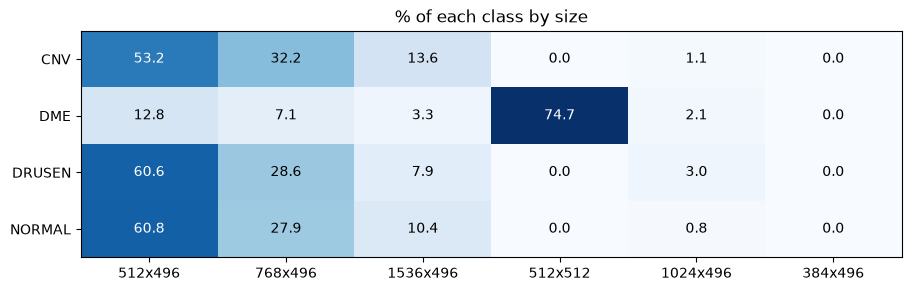

size,512x496,768x496,1536x496,512x512,1024x496,384x496,642x277,900x455
class,,,,,,,,
CNV,19912,12051,5076,0,401,15,0,0
DME,1485,818,388,8659,248,0,0,0
DRUSEN,5371,2532,699,0,262,0,1,1
NORMAL,31269,14348,5349,0,418,6,0,0


In [25]:
size_counts = pd.crosstab(raw["class"], raw["size"])
size_counts = size_counts[size_counts.sum().sort_values(ascending=False).index]  # most common size first
size_share = 100 * size_counts.div(size_counts.sum(axis=1), axis=0)
common = size_share.loc[:, size_counts.sum() >= 20]  # rare sizes are only in the table

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.imshow(common, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(common.columns)), common.columns)
ax.set_yticks(range(len(common.index)), common.index)
for i in range(len(common.index)):
    for j in range(len(common.columns)):
        value = common.iloc[i, j]
        color = "white" if value > 0.6 * common.values.max() else "black"
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", color=color)
ax.set_title("% of each class by size")
plt.show()
size_counts

### 1.5 pixel distribution by class

by percentile

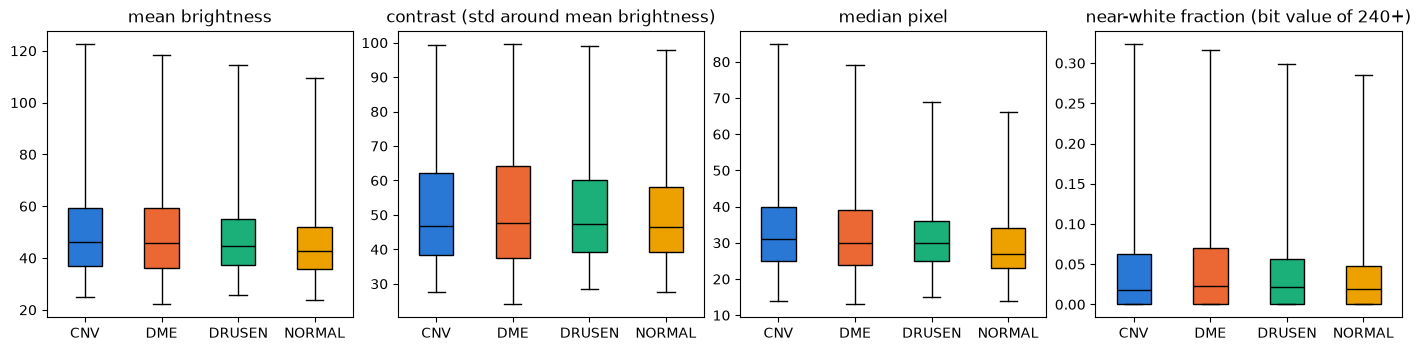

,mean,std,median,near_white
class,,,,
CNV,46.039,46.803,31.0,0.018
DME,45.799,47.781,30.0,0.022
DRUSEN,44.772,47.256,30.0,0.021
NORMAL,42.625,46.496,27.0,0.019


In [26]:
columns = ["mean", "std", "median", "near_white"]
titles = ["mean brightness", "contrast (std around mean brightness)", "median pixel", "near-white fraction (bit value of 240+)"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, column, title in zip(axes, columns, titles):
    class_boxes(ax, raw, column, title)
plt.show()
raw.groupby("class")[columns].median().round(3)

### 1.6 wedge distribution by class

white wedges, detected by the presence of a white pixel with a value of 240 or higher in a corner of the image (same as we did in `standardize.py`)

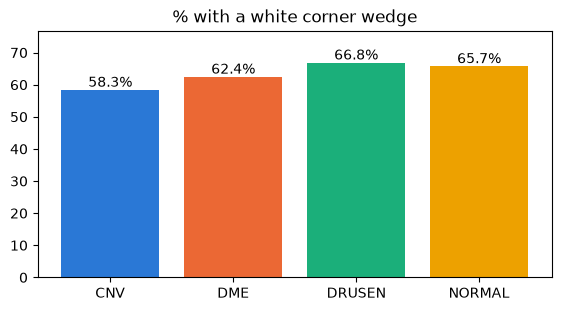

In [27]:
wedge_share = 100 * raw.groupby("class")["white_corner"].mean()
fig, ax = plt.subplots(figsize=(5.5, 3))
class_bars(ax, wedge_share, "% with a white corner wedge", fmt="{:.1f}%")
plt.show()

### 1.7 Example images per class

random sample of images, saved to to `raw_examples_by_class.png`

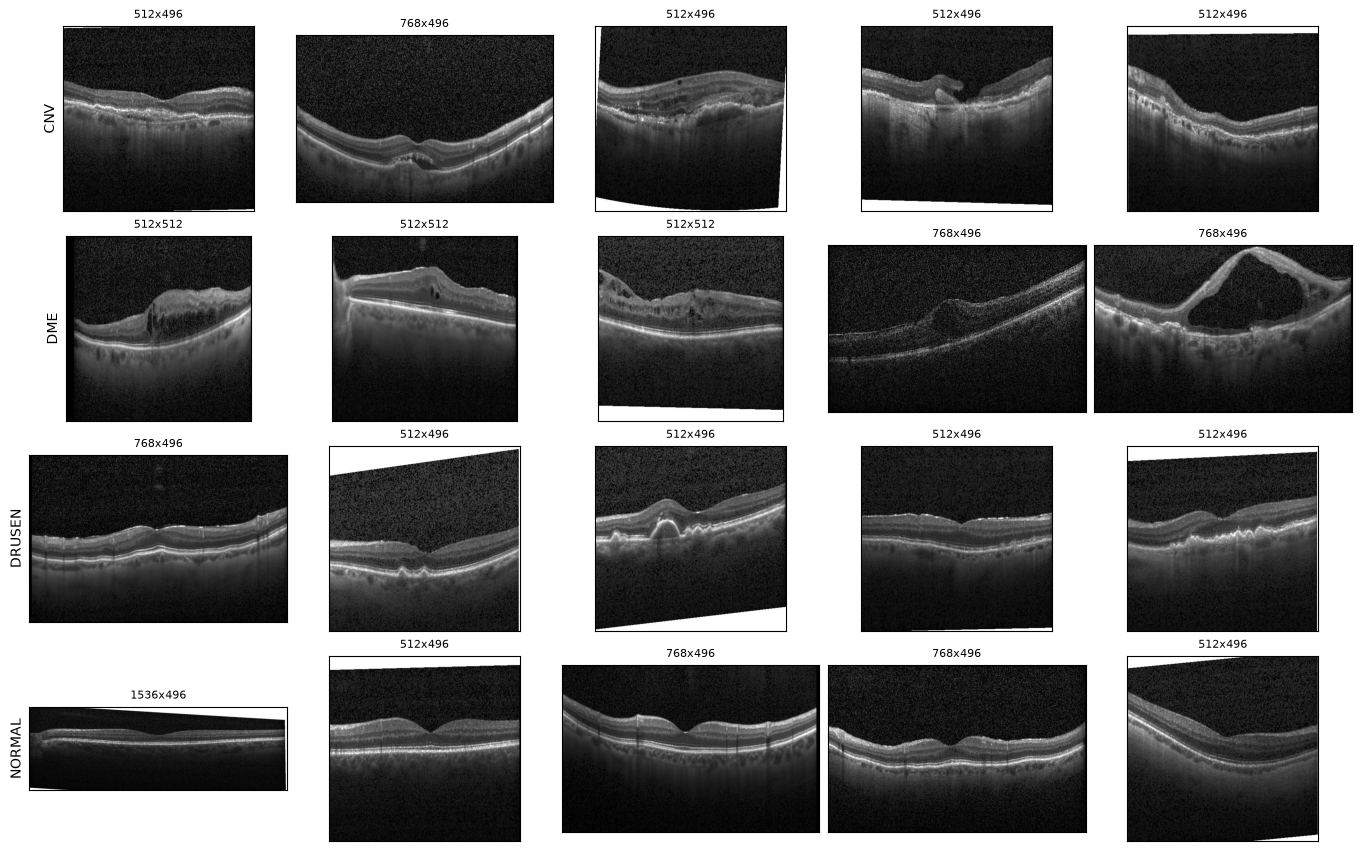

In [28]:
fig, axes = plt.subplots(4, 5, figsize=(13.5, 8.4))
for i, class_name in enumerate(CLASSES):
    picks = raw[(raw["class"] == class_name) & (raw["split"] == "train")].sample(5, random_state=SEED)
    for j in range(5):
        row = picks.iloc[j]
        show_image(axes[i, j], DATA_FOLDER / row["file"], row["size"])
    axes[i, 0].set_ylabel(class_name)
fig.savefig("raw_examples_by_class.png", dpi=150)
plt.show()

## 2. leakage and duplicates

duplicates are identical or mirrored images per the same rules as used in `dupe.py`

In [29]:
readable = hashes[hashes["readable"] == "yes"].copy()
# an image and its mirror share the smaller of their two hashes, same as match_key in dupe.py
readable["key"] = readable.apply(lambda row: min(row["pixel_hash"], row["mirror_hash"]), axis=1)


def leakage(rows):
    """counts patients in both train and test, and groups of duplicate images"""
    train_patients = set(rows.loc[rows["split"] == "train", "patient"])
    test_patients = set(rows.loc[rows["split"] == "test", "patient"])
    group_sizes = rows["key"].value_counts()
    dupes = rows[rows["key"].isin(group_sizes[group_sizes > 1].index)]
    groups = dupes.groupby("key").agg(classes=("class", "nunique"), splits=("split", "nunique"),
                                      patients=("patient", "nunique"), versions=("pixel_hash", "nunique"))
    return pd.Series({
        "patients in train and test": len(train_patients & test_patients),
        "duplicate groups": len(groups),
        "duplicate images": len(dupes),
        "conflicting labels": (groups["classes"] > 1).sum(),
        "across train/test": (groups["splits"] > 1).sum(),
        "across patients": (groups["patients"] > 1).sum(),
        "with a mirror": (groups["versions"] > 1).sum(),
    })


cleaned_rows = readable[readable["file"].isin(log["file"])]
pd.DataFrame({"raw": leakage(readable), "cleaned": leakage(cleaned_rows)})

,raw,cleaned
patients in train and test,0,0
duplicate groups,7117,25
duplicate images,15008,50
conflicting labels,269,0
across train/test,0,0
across patients,44,25
with a mirror,0,0


### 2.1 files omitted per `dupe.py`

In [30]:
print(f"{len(omit):,} images omitted")
pd.crosstab(omit["reason"], omit["class"], margins=True, margins_name="total")

8,135 images omitted


class,CNV,DME,DRUSEN,NORMAL,total
reason,,,,,
conflicting labels,208,34,248,63,553
extra copy within training,5570,404,591,1017,7582
total,5778,438,839,1080,8135


## 3. cleaned data check

reads every cleaned PNG once

In [31]:
def read_clean(output):
    """opens one cleaned png and returns its size, pixel stats and retina height"""
    with Image.open(CLEAN_FOLDER / output) as image:
        size = f"{image.width}x{image.height}"
        mode = image.mode
        gray = image.convert("L")
    pixels = np.asarray(gray)
    hist = gray.histogram()
    # assume that the retinal height can be found by looking at
    # the row of the brightest horizontal band ineach row 
    # and smoothing over 9 rows to even out all the little dots
    row_means = pixels.mean(axis=1)
    smoothed = np.convolve(row_means, np.ones(9) / 9, mode="same")
    row = {"output": output, "size": size, "mode": mode,
           "near_black": sum(hist[:6]) / pixels.size, "band_row": smoothed.argmax()}
    row.update(histogram_stats(hist))
    return row


with ThreadPoolExecutor(THREADS) as pool:
    stats = pd.DataFrame(pool.map(read_clean, log["output"]))
clean = log.merge(stats, on="output")
print(f"{len(clean):,} cleaned images")

101,174 cleaned images


### 3.1 cleaning validation

In [32]:
raw_files = set(raw["file"]) | set(failed["file"])
omitted = set(omit["file"])
logged = set(log["file"])
should_be_cleaned = raw_files - omitted
pngs = {p.relative_to(CLEAN_FOLDER).as_posix() for p in CLEAN_FOLDER.rglob("*.png")}
outputs = set(log["output"])
expected_outputs = log["file"].apply(lambda f: Path(f).with_suffix(".png").as_posix())
omitted_pngs = {Path(f).with_suffix(".png").as_posix() for f in omitted}
size = f"{standardize.OUTPUT_WIDTH}x{standardize.OUTPUT_HEIGHT}"

counts = {
    "cleaned, should be omitted": len(logged - should_be_cleaned),
    "not cleaned": len(should_be_cleaned - logged),
    "logged, no png": len(outputs - pngs),
    "png, not logged": len(pngs - outputs),
    "png in wrong folder": (expected_outputs != log["output"]).sum(),
    "omitted, has png": len(omitted_pngs & pngs),
    f"not {size} grayscale": ((clean["size"] != size) | (clean["mode"] != "L")).sum(),
}

assert all(v == 0 for v in counts.values()), f"problems found: {counts}"
print("pass")

pass


### 3.2 pixel distribution and wedges by class

near-black pixels (5 or less) come from filled in wedges (pure black), padding under short scans (pure black), and dark backgrounds (probably not pure black)

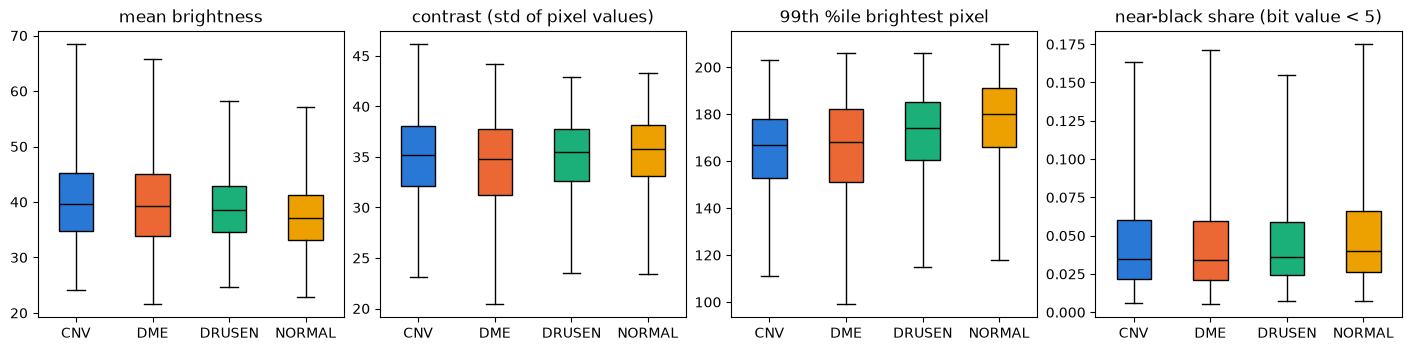

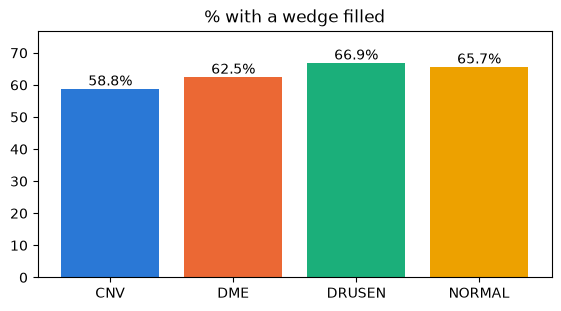

,mean,std,p99,near_black
class,,,,
CNV,39.594,35.203,167.0,0.035
DME,39.194,34.792,168.0,0.034
DRUSEN,38.529,35.442,174.0,0.036
NORMAL,37.025,35.825,180.0,0.040


In [33]:
columns = ["mean", "std", "p99", "near_black"]
titles = ["mean brightness", "contrast (std of pixel values)", "99th %ile brightest pixel", "near-black share (bit value < 5)"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, column, title in zip(axes, columns, titles):
    class_boxes(ax, clean, column, title)
plt.show()

clean["filled"] = clean["white_corners_removed"] == "yes" # whether the wedge was filled in by standardize.py
fig, ax = plt.subplots(figsize=(5.5, 3))
class_bars(ax, 100 * clean.groupby("class")["filled"].mean(), "% with a wedge filled", fmt="{:.1f}%")
plt.show()
clean.groupby("class")[columns].median().round(3)

### 3.3 retina height by class

assumes that the retinal height can be found by looking at the row of the brightest horizontal band in each row and smoothing over 9 rows to even out all the little dots in the background of each image
row 0 is the top row of the image

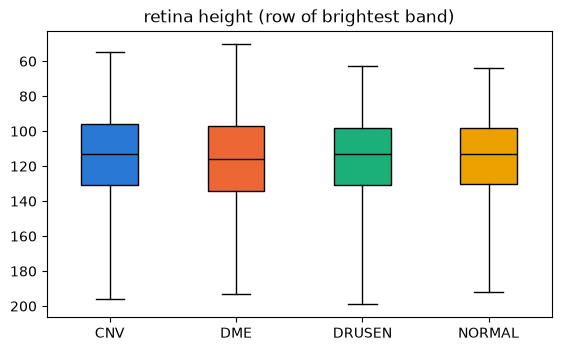

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
CNV,31677.0,115.2,28.8,4.0,96.0,113.0,131.0,243.0
DME,11160.0,116.8,29.8,4.0,97.0,116.0,134.0,235.0
DRUSEN,8027.0,116.1,27.1,4.0,98.0,113.0,131.0,233.0
NORMAL,50310.0,115.4,25.5,4.0,98.0,113.0,130.0,237.0


In [34]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
class_boxes(ax, clean, "band_row", "retina height (row of brightest band)")
ax.invert_yaxis()  # so the top of the chart is the top of the image
plt.show()
clean.groupby("class")["band_row"].describe().round(1)

### 3.4 cleaning comparison by width

compare before and after of images with different widths, saved to `cleaned_examples_by_width.png`

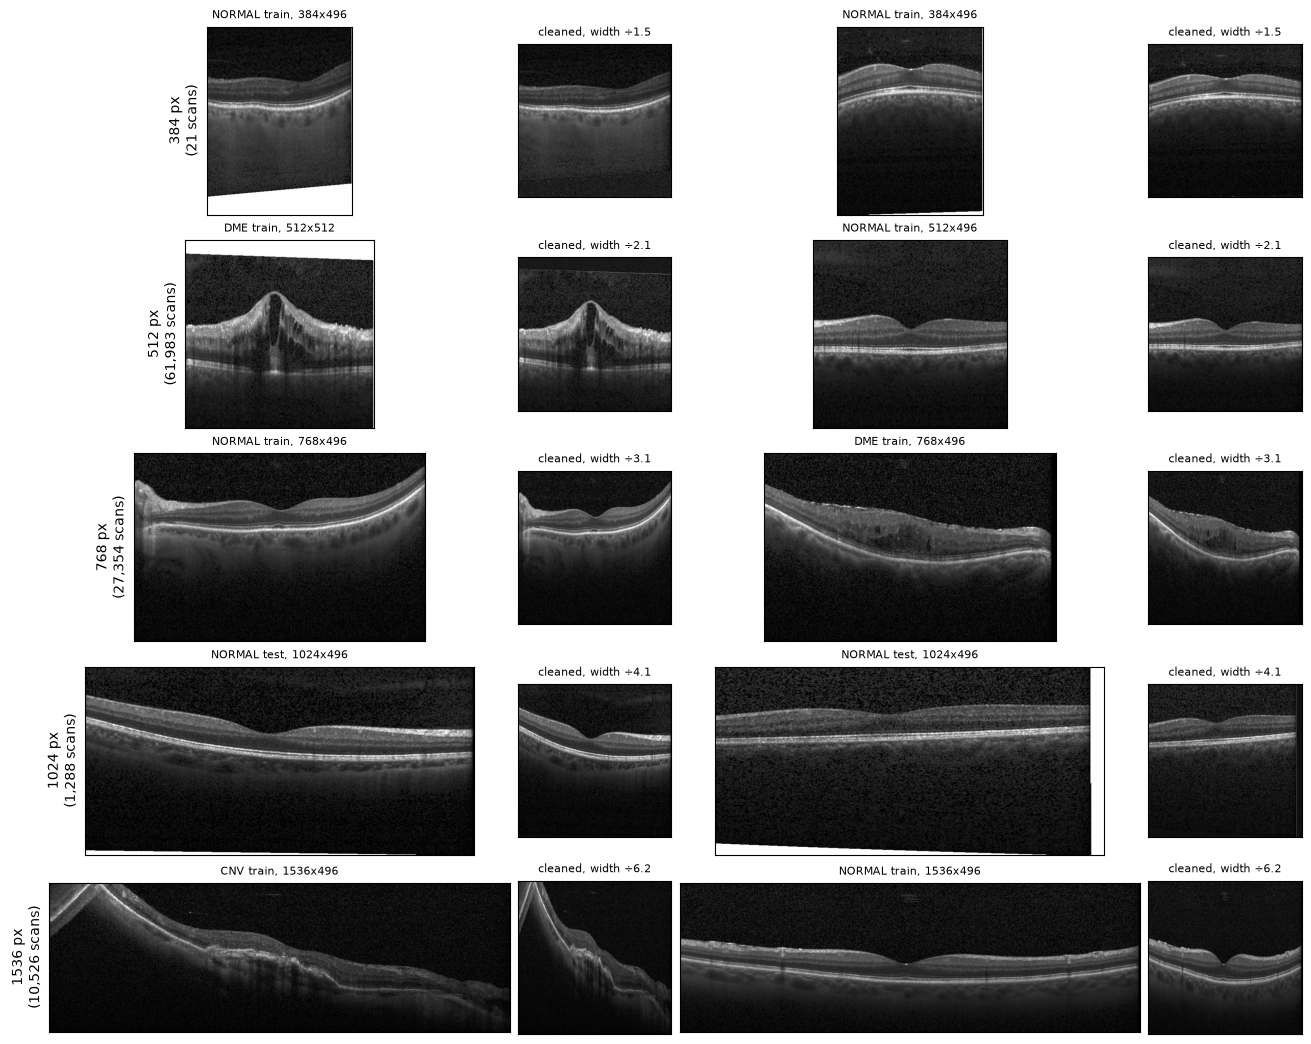

In [35]:
scans_per_width = clean["width"].value_counts().sort_index()
widths = scans_per_width[scans_per_width >= 20].index  # widths that have at least 20 examples

fig, axes = plt.subplots(len(widths), 4, figsize=(13, 2.1 * len(widths)), width_ratios=[3, 1, 3, 1])
for i, width in enumerate(widths): # loop over the widths with at least 20 scans
    picks = clean[clean["width"] == width].sample(2, random_state=SEED) # pick two random images for this width
    for k in range(2):
        row = picks.iloc[k] # pick one of the two random images for this width
        show_image(axes[i, 2 * k], DATA_FOLDER / row["file"], f"{row['class']} {row['split']}, {width}x{row['height']}") # original
        show_image(axes[i, 2 * k + 1], CLEAN_FOLDER / row["output"], f"cleaned, width ÷{width / standardize.OUTPUT_WIDTH:.1f}") # cleaned
    axes[i, 0].set_ylabel(f"{width} px\n({scans_per_width[width]:,} scans)")
fig.savefig("cleaned_examples_by_width.png", dpi=150)
plt.show()

### 3.5 cleaning comparison by class

before and after of random images that had a wedge filled in, written to `cleaned_examples_by_class.png`

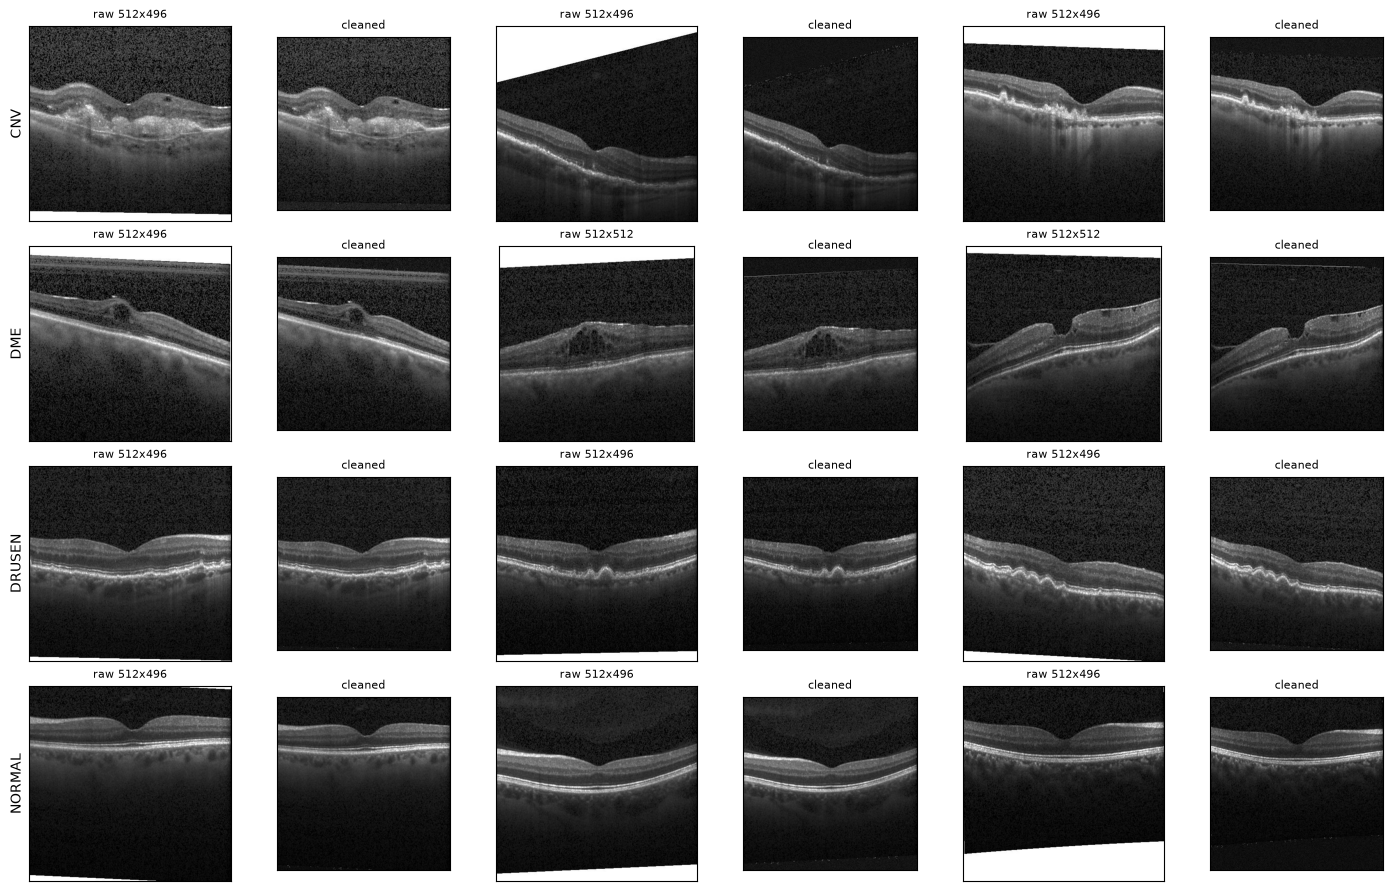

In [36]:
fig, axes = plt.subplots(4, 6, figsize=(14, 8.8), width_ratios=[1.6, 1] * 3)
for i, class_name in enumerate(CLASSES): # one row per class
    candidates = clean[(clean["class"] == class_name) & (clean["white_corners_removed"] == "yes")] # images that had a wedge filled
    picks = candidates.sample(3, random_state=SEED) # pick three random images for this class
    for k in range(3):
        row = picks.iloc[k]
        show_image(axes[i, 2 * k], DATA_FOLDER / row["file"], f"raw {row['width']}x{row['height']}") # original
        show_image(axes[i, 2 * k + 1], CLEAN_FOLDER / row["output"], "cleaned") # cleaned
    axes[i, 0].set_ylabel(class_name)
fig.savefig("cleaned_examples_by_class.png", dpi=150)
plt.show()